<a href="https://colab.research.google.com/github/wUssopp/Eksploracja-Danych/blob/main/EDA_lab5_ceny_domow_Ames.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Eksploracyjna analiza danych: ceny domów w Ames (Iowa)

Eksploracja danych, zadanie do wykładu 5 (EDA).

Dane pochodzą z konkursu Kaggle [House Prices: Advanced Regression Techniques](https://www.kaggle.com/c/house-prices-advanced-regression-techniques). Plik `train.csv` zawiera 1460 transakcji sprzedaży domów z lat 2006-2010 i 81 kolumn, a znaczenie kolumn jest opisane w `data_description.txt`.

Cel: poznać dane, zanim zacznie się budować model wyceny. Sprawdzam, co jest w zbiorze, jakiej jakości są dane, jak rozkłada się cena i od czego zależy.

Plan:
1. Wczytanie danych
2. Typy zmiennych i statystyki opisowe
3. Jakość i zakres danych
4. Braki danych i co oznaczają
5. Zmienna docelowa `SalePrice`
6. Wykresy podobne do tych z wykładu
7. Hipoteza: większe domy są droższe
8. Inne zależności
9. Podsumowanie

## 1. Wczytanie danych

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from pathlib import Path

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 200)

W Colabie trzeba wgrać `train.csv` i `data_description.txt`. Jeśli plików nie ma w katalogu, komórka niżej otworzy okno wgrywania.

In [2]:
potrzebne = ["train.csv", "data_description.txt"]
if not all(Path(p).exists() for p in potrzebne):
    from google.colab import files
    files.upload()

Wczytuję z `keep_default_na=False` i `na_values=["NA"]`. Pandas domyślnie zamienia na NaN nie tylko tekst "NA", ale też "None", a w kolumnie `MasVnrType` "None" jest zwykłą kategorią (dom nie ma okładziny murowanej). Za braki uznaję więc tylko "NA" i puste pola.

In [3]:
df = pd.read_csv("train.csv", keep_default_na=False, na_values=["NA"])
df.shape

(1460, 81)

In [4]:
domyslnie = pd.read_csv("train.csv")
print("MasVnrType, braki przy domyślnym read_csv:", domyslnie["MasVnrType"].isna().sum())
print("MasVnrType, braki przy na_values=['NA']:  ", df["MasVnrType"].isna().sum())
df["MasVnrType"].value_counts(dropna=False)

MasVnrType, braki przy domyślnym read_csv: 872
MasVnrType, braki przy na_values=['NA']:   8


,count
MasVnrType,
None,864
BrkFace,445
Stone,128
BrkCmn,15
NaN,8


Przy domyślnym wczytaniu 864 domy z wartością "None" zamieniłyby się w braki i wyglądałoby, że w tej kolumnie brakuje 60% danych. Naprawdę brakuje tylko 8 wartości.

In [5]:
df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,None,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,None,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,Ex,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,2000.0,RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


## 2. Typy zmiennych i statystyki opisowe

In [6]:
df.dtypes.value_counts()

,count
object,43
int64,35
float64,3


In [7]:
liczbowe = df.select_dtypes("number").columns.drop(["Id", "SalePrice"])
tekstowe = df.select_dtypes(exclude="number").columns

print(len(liczbowe), "kolumn liczbowych:")
print(list(liczbowe))
print()
print(len(tekstowe), "kolumn tekstowych:")
print(list(tekstowe))

36 kolumn liczbowych:
['MSSubClass', 'LotFrontage', 'LotArea', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'TotRmsAbvGrd', 'Fireplaces', 'GarageYrBlt', 'GarageCars', 'GarageArea', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea', 'MiscVal', 'MoSold', 'YrSold']

43 kolumn tekstowych:
['MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'Heating', 'HeatingQC', 'CentralAir', 'Electrical', 'KitchenQual', 'Functional', 'FireplaceQu', 'GarageTy

In [8]:
df.dtypes.to_frame("typ").T

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
typ,int64,int64,object,float64,int64,object,object,object,object,object,object,object,object,object,object,object,object,int64,int64,int64,int64,object,object,object,object,object,float64,object,object,object,object,object,object,object,int64,object,int64,int64,int64,object,object,object,object,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,object,int64,object,int64,object,object,float64,object,int64,int64,object,object,object,int64,int64,int64,int64,int64,int64,object,object,object,int64,int64,int64,object,object,int64


In [9]:
skala = {"Po", "Fa", "TA", "Gd", "Ex"}
porzadkowe_tekstowe = [c for c in tekstowe if set(df[c].dropna()) <= skala]
print("Tekstowe ze skalą Po < Fa < TA < Gd < Ex:", porzadkowe_tekstowe)
print()
print("Liczbowe, które tak naprawdę są kategoriami:")
print(df[["MSSubClass", "OverallQual", "OverallCond", "MoSold"]].nunique())

Tekstowe ze skalą Po < Fa < TA < Gd < Ex: ['ExterQual', 'ExterCond', 'BsmtQual', 'BsmtCond', 'HeatingQC', 'KitchenQual', 'FireplaceQu', 'GarageQual', 'GarageCond', 'PoolQC']

Liczbowe, które tak naprawdę są kategoriami:
MSSubClass     15
OverallQual    10
OverallCond     9
MoSold         12
dtype: int64


### Pytania naprowadzające

**Jaka jest zmienna docelowa?**
`SalePrice`, czyli cena sprzedaży domu w USD. To ją model ma przewidywać. `Id` to tylko numer wiersza i nic nie mówi o domu, więc nie biorę go do analizy.

**Jakie rodzaje zmiennych są w zbiorze?**
Pandas widzi 36 kolumn liczbowych (bez `Id` i ceny) i 43 tekstowe. Po przeczytaniu opisu podział wygląda trochę inaczej:
- liczbowe ciągłe: powierzchnie (`LotArea`, `GrLivArea`, `TotalBsmtSF`, `GarageArea` itd.), `LotFrontage`, `MiscVal`,
- liczbowe dyskretne: liczba łazienek, sypialni, pokoi, miejsc w garażu, kominków,
- daty: `YearBuilt`, `YearRemodAdd`, `GarageYrBlt`, `YrSold`, `MoSold`,
- porządkowe zapisane liczbami: `OverallQual` i `OverallCond` (skala 1-10),
- porządkowe zapisane tekstem: 10 kolumn ze skalą Po < Fa < TA < Gd < Ex (np. `ExterQual`, `KitchenQual`), a poza tym np. `BsmtExposure`, `BsmtFinType1`, `Functional`,
- nominalne: dzielnica, typ budynku, strefa zabudowy, materiały, rodzaj sprzedaży itd.

Pułapka: `MSSubClass` jest zapisana liczbami (20, 60, 120...), ale to kody typu budynku, więc np. średnia z tej kolumny nie ma żadnego sensu.

Kolumn z prawdziwym tekstem (opisy, komentarze) nie ma. Wszystkie kolumny tekstowe to krótkie kody kategorii.

In [10]:
df.describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
Id,1460.0,730.5,421.6,1.0,365.8,730.5,1095.2,1460.0
MSSubClass,1460.0,56.9,42.3,20.0,20.0,50.0,70.0,190.0
LotFrontage,1201.0,70.0,24.3,21.0,59.0,69.0,80.0,313.0
LotArea,1460.0,10516.8,9981.3,1300.0,7553.5,9478.5,11601.5,215245.0
OverallQual,1460.0,6.1,1.4,1.0,5.0,6.0,7.0,10.0
OverallCond,1460.0,5.6,1.1,1.0,5.0,5.0,6.0,9.0
YearBuilt,1460.0,1971.3,30.2,1872.0,1954.0,1973.0,2000.0,2010.0
YearRemodAdd,1460.0,1984.9,20.6,1950.0,1967.0,1994.0,2004.0,2010.0
MasVnrArea,1452.0,103.7,181.1,0.0,0.0,0.0,166.0,1600.0
BsmtFinSF1,1460.0,443.6,456.1,0.0,0.0,383.5,712.2,5644.0


Co widać w `describe()`:
- `count` mniejszy niż 1460 mają `LotFrontage` (1201), `MasVnrArea` (1452) i `GarageYrBlt` (1379). To są braki w kolumnach liczbowych, wracam do nich w części 4.
- Powierzchnie są w stopach kwadratowych, ceny w dolarach. Wartości wyglądają sensownie: domy zbudowane w latach 1872-2010, sprzedane w 2006-2010.
- `YearRemodAdd` zaczyna się dokładnie od 1950 i aż 178 domów ma ten rok (a rok 1951 tylko 4). Wygląda na to, że starsze daty remontu zapisano jako 1950, więc ta kolumna jest ucięta od dołu.
- W wielu kolumnach mediana to 0 (np. `2ndFlrSF`, `MasVnrArea`, `PoolArea`), bo większość domów nie ma piętra, okładziny czy basenu. Zero znaczy tu brak cechy, a nie błąd.
- Max mocno odstaje od Q3 w `LotArea` (215 245 stóp² przy Q3 = 11 602) i w `GrLivArea` (5642 przy Q3 = 1777). Te domy sprawdzam niżej.

In [11]:
opis_tekst = df.describe(exclude="number").T
opis_tekst["udzial_najczestszej"] = (opis_tekst["freq"].astype(int) / len(df)).round(3)
opis_tekst.sort_values("udzial_najczestszej", ascending=False).head(10)

,count,unique,top,freq,udzial_najczestszej
Utilities,1460,2,AllPub,1459,0.999
Street,1460,2,Pave,1454,0.996
Condition2,1460,8,Norm,1445,0.990
RoofMatl,1460,8,CompShg,1434,0.982
Heating,1460,6,GasA,1428,0.978
LandSlope,1460,3,Gtl,1382,0.947
CentralAir,1460,2,Y,1365,0.935
Functional,1460,7,Typ,1360,0.932
PavedDrive,1460,3,Y,1340,0.918
Electrical,1459,5,SBrkr,1334,0.914


Część kolumn tekstowych prawie się nie zmienia: `Utilities` ma tę samą wartość w 1459 domach na 1460, `Street` w 1454, `Condition2` w 1445. Takie kolumny niewiele wniosą do modelu, bo nie odróżniają domów od siebie.

## 3. Jakość i zakres danych

Sprawdzam kilka rzeczy, które powinny się zgadzać z samej definicji kolumn.

In [12]:
print("duplikaty wierszy:", df.duplicated().sum(), "| Id unikalne:", df["Id"].is_unique)
print("GrLivArea = 1stFlrSF + 2ndFlrSF + LowQualFinSF:",
      (df["1stFlrSF"] + df["2ndFlrSF"] + df["LowQualFinSF"] == df["GrLivArea"]).all())
print("TotalBsmtSF = BsmtFinSF1 + BsmtFinSF2 + BsmtUnfSF:",
      (df["BsmtFinSF1"] + df["BsmtFinSF2"] + df["BsmtUnfSF"] == df["TotalBsmtSF"]).all())
print("remont przed budową:", (df["YearRemodAdd"] < df["YearBuilt"]).sum())
print("sprzedaż przed budową:", (df["YrSold"] < df["YearBuilt"]).sum())
print("garaż starszy niż dom:", (df["GarageYrBlt"] < df["YearBuilt"]).sum())
print("MasVnrType = None, ale MasVnrArea > 0:", ((df["MasVnrType"] == "None") & (df["MasVnrArea"] > 0)).sum())
print("lata sprzedaży:", df["YrSold"].min(), "-", df["YrSold"].max(),
      "| ostatni miesiąc w 2010:", df.loc[df["YrSold"] == 2010, "MoSold"].max())

duplikaty wierszy: 0 | Id unikalne: True
GrLivArea = 1stFlrSF + 2ndFlrSF + LowQualFinSF: True
TotalBsmtSF = BsmtFinSF1 + BsmtFinSF2 + BsmtUnfSF: True
remont przed budową: 0
sprzedaż przed budową: 0
garaż starszy niż dom: 9
MasVnrType = None, ale MasVnrArea > 0: 5
lata sprzedaży: 2006 - 2010 | ostatni miesiąc w 2010: 7


Dane są spójne: nie ma duplikatów, sumy powierzchni się zgadzają, nie ma remontu ani sprzedaży przed budową. Drobne dziwności:
- 9 domów ma garaż starszy niż dom. To jest możliwe (np. nowy dom na działce ze starym garażem), więc tego nie ruszam.
- 5 domów ma `MasVnrType = None`, ale dodatnią powierzchnię okładziny, więc jedna z tych wartości jest błędna. To bardzo mało, tylko odnotowuję.
- Dane kończą się w lipcu 2010, więc rok 2010 jest niepełny. Trzeba o tym pamiętać przy porównywaniu lat.

Porównuję jeszcze kody kategorii w danych z kodami z `data_description.txt`.

In [13]:
opis_kodow = {}
kolumna = None
for linia in Path("data_description.txt").read_text(encoding="latin-1").splitlines():
    if linia and not linia[0].isspace() and ":" in linia:
        kolumna = linia.split(":")[0]
        opis_kodow[kolumna] = set()
    elif linia.strip() and kolumna:
        opis_kodow[kolumna].add(linia.strip().split("\t")[0].strip())

for c in tekstowe:
    if c in opis_kodow:
        spoza_opisu = set(df[c].dropna()) - opis_kodow[c]
        if spoza_opisu:
            print(f"{c}: w danych {sorted(spoza_opisu)}, w opisie {sorted(opis_kodow[c] - set(df[c]))}")

MSZoning: w danych ['C (all)'], w opisie ['A', 'C', 'I', 'RP']
Neighborhood: w danych ['NAmes'], w opisie ['Names']
BldgType: w danych ['2fmCon', 'Duplex', 'Twnhs'], w opisie ['2FmCon', 'Duplx', 'TwnhsI']
Exterior2nd: w danych ['Brk Cmn', 'CmentBd', 'Wd Shng'], w opisie ['BrkComm', 'CemntBd', 'PreCast', 'WdShing']


W 4 kolumnach opis nie zgadza się z danymi, ale to tylko inna pisownia tych samych kategorii (`NAmes` zamiast `Names`, `Duplex` zamiast `Duplx`, `C (all)` zamiast `C`, `Wd Shng` zamiast `WdShing`). Kategorii, których nie ma w opisie, nie znalazłem. Gdyby trzeba było łączyć dane z opisem automatycznie, te nazwy trzeba by ujednolicić.

### Zakres danych

In [14]:
print(df["BldgType"].value_counts())
print()
mediana_sf = df["GrLivArea"].median()
print(f"mediana powierzchni mieszkalnej: {mediana_sf:.0f} stóp² = {mediana_sf * 0.0929:.0f} m²")
print(f"mediana powierzchni działki: {df['LotArea'].median():.0f} stóp² = {df['LotArea'].median() * 0.0929:.0f} m²")

BldgType
1Fam      1220
TwnhsE     114
Duplex      52
Twnhs       43
2fmCon      31
Name: count, dtype: int64

mediana powierzchni mieszkalnej: 1464 stóp² = 136 m²
mediana powierzchni działki: 9478 stóp² = 881 m²


Zbiór to głównie domy jednorodzinne (1220 z 1460), poza tym szeregowce, duplexy i domy dwurodzinne. Mieszkań w blokach nie ma wcale, więc model zbudowany na tych danych nie nadawałby się do wyceny mieszkań, które w Polsce są najpopularniejsze. Do tego to jedno miasto w USA i lata 2006-2010.

Typowy dom ma ok. 136 m² powierzchni mieszkalnej i działkę ok. 880 m². W dalszej części zostawiam stopy², bo przeliczenie na m² nie zmienia żadnych zależności.

## 4. Braki danych i co oznaczają

In [15]:
braki = df.isna().sum()
braki = braki[braki > 0].sort_values(ascending=False)
tabela_brakow = pd.DataFrame({
    "braki": braki,
    "procent": (braki / len(df) * 100).round(1),
    "NA opisane w data_description": [("NA" in opis_kodow.get(c, set())) for c in braki.index],
})
tabela_brakow

,braki,procent,NA opisane w data_description
PoolQC,1453,99.5,True
MiscFeature,1406,96.3,True
Alley,1369,93.8,True
Fence,1179,80.8,True
FireplaceQu,690,47.3,True
LotFrontage,259,17.7,False
GarageCond,81,5.5,True
GarageType,81,5.5,True
GarageYrBlt,81,5.5,False
GarageFinish,81,5.5,True


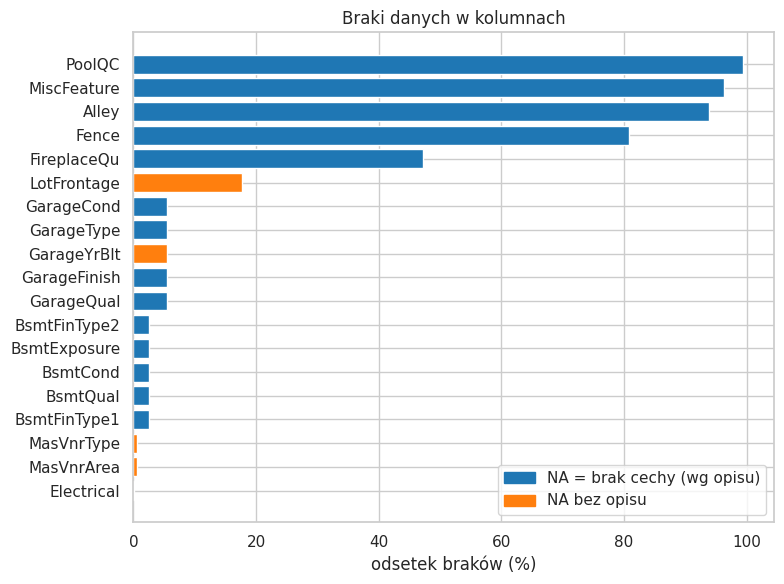

In [16]:
fig, ax = plt.subplots(figsize=(8, 6))
kolory = np.where(tabela_brakow["NA opisane w data_description"], "tab:blue", "tab:orange")
ax.barh(tabela_brakow.index, tabela_brakow["procent"], color=kolory)
ax.invert_yaxis()
ax.set_xlabel("odsetek braków (%)")
ax.set_title("Braki danych w kolumnach")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color="tab:blue"), plt.Rectangle((0, 0), 1, 1, color="tab:orange")],
          labels=["NA = brak cechy (wg opisu)", "NA bez opisu"], loc="lower right")
plt.tight_layout()
plt.show()

Na pierwszy rzut oka braków jest bardzo dużo: `PoolQC` 99,5%, `MiscFeature` 96%, `Alley` 94%, `Fence` 81%. Ale według `data_description.txt` w tych kolumnach NA oznacza, że dom nie ma danej rzeczy: basenu, alejki, płotu, kominka, garażu, piwnicy. Takich wierszy nie można usuwać ani uzupełniać średnią czy modą, bo NA niesie tu prawdziwą informację o domu.

Sprawdzam, czy liczba braków zgadza się z liczbą domów bez danej cechy:

In [17]:
print("domy bez piwnicy (TotalBsmtSF = 0):", (df["TotalBsmtSF"] == 0).sum())
print("domy bez garażu (GarageArea = 0):  ", (df["GarageArea"] == 0).sum())
print("domy bez kominka (Fireplaces = 0): ", (df["Fireplaces"] == 0).sum())
print("domy bez basenu (PoolArea = 0):    ", (df["PoolArea"] == 0).sum())

piwnica = ["BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1", "BsmtFinType2"]
garaz = ["GarageType", "GarageYrBlt", "GarageFinish", "GarageQual", "GarageCond"]
print()
print("braki w kolumnach piwnicy u domów z piwnicą:")
print(df.loc[df["TotalBsmtSF"] > 0, piwnica].isna().sum())
print()
print("braki w kolumnach garażu u domów z garażem:", df.loc[df["GarageArea"] > 0, garaz].isna().sum().sum())

domy bez piwnicy (TotalBsmtSF = 0): 37
domy bez garażu (GarageArea = 0):   81
domy bez kominka (Fireplaces = 0):  690
domy bez basenu (PoolArea = 0):     1453

braki w kolumnach piwnicy u domów z piwnicą:
BsmtQual        0
BsmtCond        0
BsmtExposure    1
BsmtFinType1    0
BsmtFinType2    1
dtype: int64

braki w kolumnach garażu u domów z garażem: 0


Zgadza się prawie idealnie: 37 domów bez piwnicy i 37 braków w kolumnach piwnicy, 81 domów bez garażu i 81 braków w kolumnach garażu, 690 bez kominka, 1453 bez basenu. Wyjątek to dwa domy, które mają piwnicę, a brakuje im `BsmtExposure` albo `BsmtFinType2`. To już są prawdziwe braki. Poniżej wszystkie wiersze z prawdziwymi brakami (bez `LotFrontage`):

In [18]:
df.loc[df[["MasVnrType", "Electrical"]].isna().any(axis=1)
       | ((df["TotalBsmtSF"] > 0) & df[piwnica].isna().any(axis=1)),
       ["Id", "MasVnrType", "MasVnrArea", "Electrical", "TotalBsmtSF", "BsmtExposure", "BsmtFinType2"]]

,Id,MasVnrType,MasVnrArea,Electrical,TotalBsmtSF,BsmtExposure,BsmtFinType2
234,235,NaN,NaN,SBrkr,860,No,Unf
332,333,BrkFace,296.0,SBrkr,3206,No,NaN
529,530,NaN,NaN,SBrkr,2035,No,Unf
650,651,NaN,NaN,SBrkr,813,No,Unf
936,937,NaN,NaN,SBrkr,1176,No,Unf
948,949,BrkFace,144.0,SBrkr,936,NaN,Unf
973,974,NaN,NaN,SBrkr,1428,No,Unf
977,978,NaN,NaN,SBrkr,1241,No,Unf
1243,1244,NaN,NaN,SBrkr,2076,Gd,Unf
1278,1279,NaN,NaN,SBrkr,1128,No,Unf


Prawdziwe braki poza `LotFrontage` ma 11 domów: 8 bez informacji o okładzinie (brakuje i typu, i powierzchni), 1 bez typu instalacji elektrycznej i 2 z pojedynczym brakiem w opisie piwnicy.

Tworzę kopię danych `dane`, w której NA oznaczające brak cechy zamieniam na kategorię "Brak", a prawdziwe braki zostawiam jako NaN.

In [19]:
dane = df.copy()
for c in ["Alley", "Fence", "MiscFeature"]:
    dane[c] = dane[c].fillna("Brak")
dane.loc[dane["PoolArea"] == 0, "PoolQC"] = "Brak"
dane.loc[dane["Fireplaces"] == 0, "FireplaceQu"] = "Brak"
dane.loc[dane["GarageArea"] == 0, ["GarageType", "GarageFinish", "GarageQual", "GarageCond"]] = "Brak"
dane.loc[dane["TotalBsmtSF"] == 0, piwnica] = "Brak"

zostalo = dane.isna().sum()
zostalo[zostalo > 0].sort_values(ascending=False)

,0
LotFrontage,259
GarageYrBlt,81
MasVnrType,8
MasVnrArea,8
BsmtExposure,1
BsmtFinType2,1
Electrical,1


Zostały tylko:
- `LotFrontage` (259 domów, 17,7%). Opis nic nie mówi o NA w tej kolumnie, a każdy dom ma jakąś granicę z ulicą, więc to zwykły brak danych. Przy budowie modelu uzupełniłbym go medianą w danej dzielnicy, bo działki w jednej dzielnicy są do siebie podobne.
- `GarageYrBlt` (81), czyli domy bez garażu. Roku budowy garażu, którego nie ma, nie da się sensownie wpisać, więc zostaje NaN.
- pojedyncze braki w `MasVnrType`, `MasVnrArea`, `BsmtExposure`, `BsmtFinType2` i `Electrical`. Jest ich tak mało, że nie wpływają na wyniki EDA.

W tym notatniku niczego nie imputuję, bo to tylko eksploracja. Dalej pracuję na `dane`.

## 5. Zmienna docelowa: SalePrice

In [20]:
cena = dane["SalePrice"]
q1, q3 = cena.quantile([0.25, 0.75])
iqr = q3 - q1

statystyki = pd.Series({
    "min": cena.min(),
    "Q1": q1,
    "mediana": cena.median(),
    "średnia": cena.mean(),
    "Q3": q3,
    "max": cena.max(),
    "IQR": iqr,
    "odch. std.": cena.std(),
    "skośność": cena.skew(),
    "kurtoza": cena.kurt(),
})
statystyki.map(lambda x: f"{x:,.0f}".replace(",", " ") if abs(x) > 100 else f"{x:.2f}")

,0
min,34 900
Q1,129 975
mediana,163 000
średnia,180 921
Q3,214 000
max,755 000
IQR,84 025
odch. std.,79 443
skośność,1.88
kurtoza,6.54


Średnia cena to 180 921 USD, mediana 163 000 USD. Środkowa połowa domów kosztuje od ok. 130 tys. do 214 tys. (IQR = 84 tys.). Najtańszy dom kosztował 34 900, a najdroższy 755 000.

### Histogram cen dla różnej liczby przedziałów

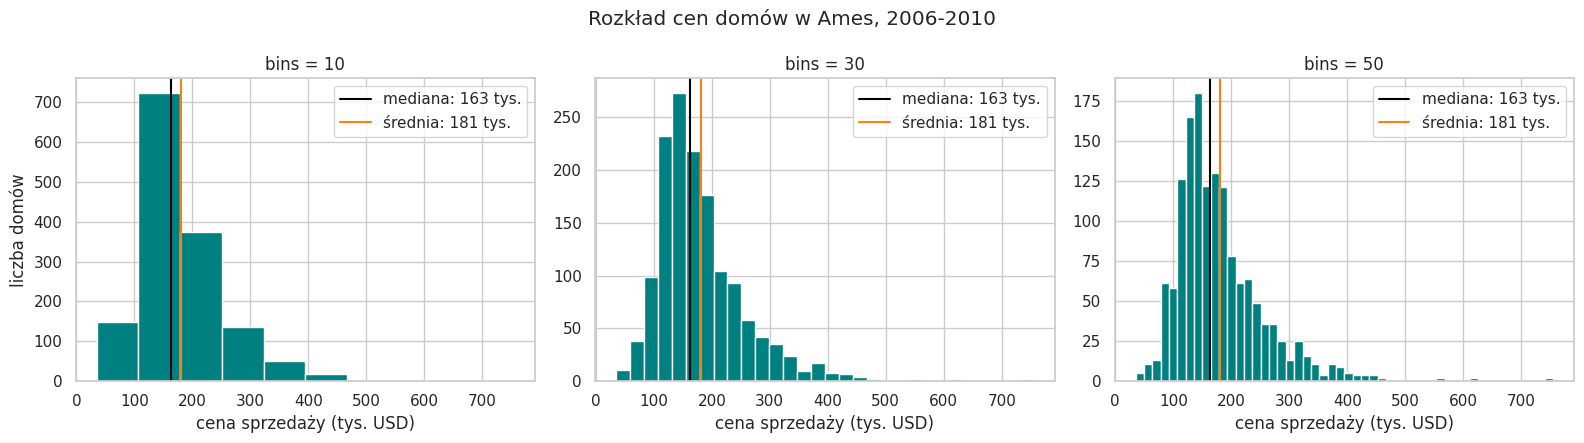

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=False)
for ax, bins in zip(axes, [10, 30, 50]):
    ax.hist(cena / 1000, bins=bins, color="teal", edgecolor="white")
    ax.axvline(cena.median() / 1000, color="black", lw=1.5, label=f"mediana: {cena.median() / 1000:.0f} tys.")
    ax.axvline(cena.mean() / 1000, color="tab:orange", lw=1.5, label=f"średnia: {cena.mean() / 1000:.0f} tys.")
    ax.set_title(f"bins = {bins}")
    ax.set_xlabel("cena sprzedaży (tys. USD)")
    ax.legend()
axes[0].set_ylabel("liczba domów")
fig.suptitle("Rozkład cen domów w Ames, 2006-2010")
plt.tight_layout()
plt.show()

Przy 10 przedziałach widać tylko ogólny kształt i jeden wysoki słupek. Według mnie najlepszy obraz daje 30 przedziałów. Przy 50 robią się dziury i ząbki, które są już szumem. Niezależnie od liczby przedziałów rozkład jest prawostronnie skośny: większość domów kosztuje od 100 do 250 tys., a w prawo ciągnie się długi ogon drogich domów. Przez ten ogon średnia jest o 18 tys. wyższa od mediany.

### Wykres pudełkowy cen

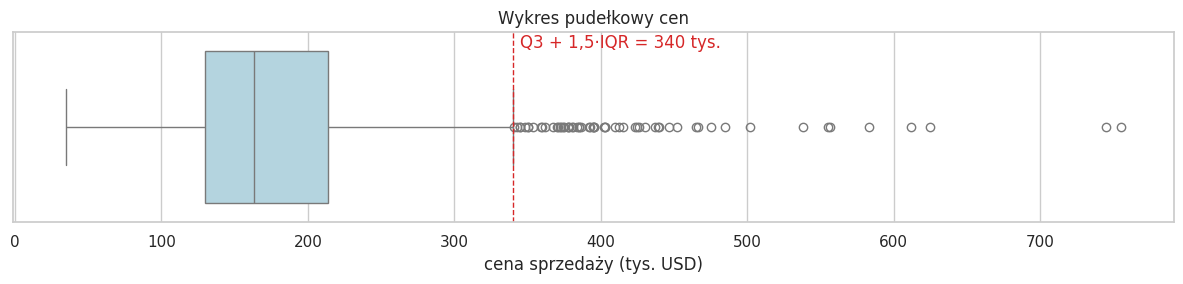

dolny płot: 3,938, górny płot: 340,038
domów poniżej dolnego płotu: 0
domów powyżej górnego płotu: 61 (4.2%)


In [22]:
gorny_plot = q3 + 1.5 * iqr
dolny_plot = q1 - 1.5 * iqr

fig, ax = plt.subplots(figsize=(12, 3))
sns.boxplot(x=cena / 1000, color="lightblue", ax=ax)
ax.axvline(gorny_plot / 1000, color="tab:red", ls="--", lw=1)
ax.text(gorny_plot / 1000 + 5, -0.42, f"Q3 + 1,5·IQR = {gorny_plot / 1000:.0f} tys.", color="tab:red")
ax.set_xlabel("cena sprzedaży (tys. USD)")
ax.set_title("Wykres pudełkowy cen")
plt.tight_layout()
plt.show()

print(f"dolny płot: {dolny_plot:,.0f}, górny płot: {gorny_plot:,.0f}")
print("domów poniżej dolnego płotu:", (cena < dolny_plot).sum())
print("domów powyżej górnego płotu:", (cena > gorny_plot).sum(), f"({(cena > gorny_plot).mean():.1%})")

Wartości odstające są tylko po prawej stronie: 61 domów (4,2%) kosztuje więcej niż 340 tys. Dolny płot wychodzi ok. 4 tys., więc tanich odstających nie ma. Co to za drogie domy?

In [23]:
drogie = dane[cena > gorny_plot]
porownanie = pd.DataFrame({
    "drogie domy": drogie[["SalePrice", "GrLivArea", "OverallQual", "YearBuilt", "GarageCars"]].median(),
    "wszystkie": dane[["SalePrice", "GrLivArea", "OverallQual", "YearBuilt", "GarageCars"]].median(),
})
print(porownanie)
print()
print("dzielnice drogich domów:")
print(drogie["Neighborhood"].value_counts().head(5))
print()
print("ocena jakości drogich domów:")
print(drogie["OverallQual"].value_counts().sort_index())

             drogie domy  wszystkie
SalePrice       394617.0   163000.0
GrLivArea         2364.0     1464.0
OverallQual          9.0        6.0
YearBuilt         2006.0     1973.0
GarageCars           3.0        2.0

dzielnice drogich domów:
Neighborhood
NridgHt    27
NoRidge    11
StoneBr     9
Crawfor     3
Timber      3
Name: count, dtype: int64

ocena jakości drogich domów:
OverallQual
7      3
8     22
9     23
10    13
Name: count, dtype: int64


To nie są błędy. Drogie domy mają medianę jakości 9 zamiast 6, są ok. 60% większe (2364 wobec 1464 stóp²), prawie wszystkie zbudowano niedawno (mediana roku budowy 2006) i stoją głównie w trzech dzielnicach: NridgHt, NoRidge i StoneBr. Po prostu duże, nowe domy w najlepszych dzielnicach. Usunięcie ich tylko dlatego, że wypadają za płotem, byłoby błędem, bo model nic by nie wiedział o drogim segmencie rynku.

### Czy ceny mają rozkład normalny?

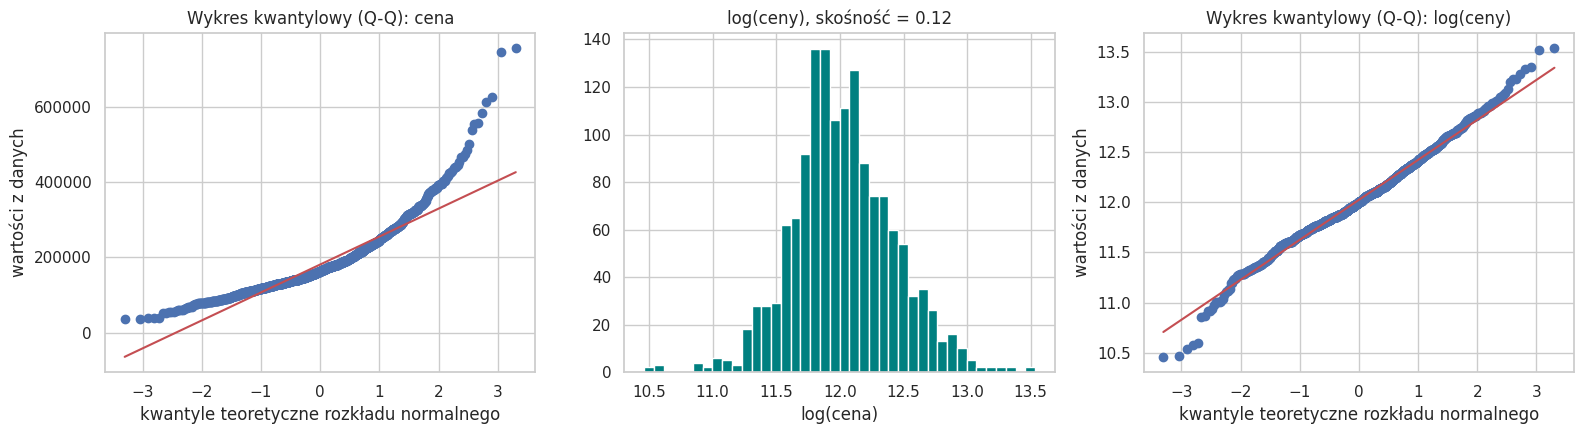

skośność ceny: 1.88, po logarytmie: 0.12


In [24]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
stats.probplot(cena, dist="norm", plot=axes[0])
axes[0].set_title("Wykres kwantylowy (Q-Q): cena")
axes[1].hist(np.log(cena), bins=40, color="teal", edgecolor="white")
axes[1].set_title(f"log(ceny), skośność = {np.log(cena).skew():.2f}")
axes[1].set_xlabel("log(cena)")
stats.probplot(np.log(cena), dist="norm", plot=axes[2])
axes[2].set_title("Wykres kwantylowy (Q-Q): log(ceny)")
for ax in axes[[0, 2]]:
    ax.set_xlabel("kwantyle teoretyczne rozkładu normalnego")
    ax.set_ylabel("wartości z danych")
plt.tight_layout()
plt.show()

print(f"skośność ceny: {cena.skew():.2f}, po logarytmie: {np.log(cena).skew():.2f}")

Nie. Histogram nie jest symetryczny, skośność wynosi 1,88 (dla rozkładu normalnego 0), a kurtoza 6,5 oznacza grube ogony. Na wykresie Q-Q punkty po prawej stronie wyraźnie odjeżdżają w górę od prostej. Po zlogarytmowaniu skośność spada do 0,12 i punkty prawie leżą na prostej. Przy modelu regresji lepiej więc przewidywać log(ceny). Konkurs na Kaggle i tak liczy błąd na logarytmie ceny.

## 6. Wykresy podobne do tych z wykładu

### Wykres pudełkowy: cena a ogólna jakość domu

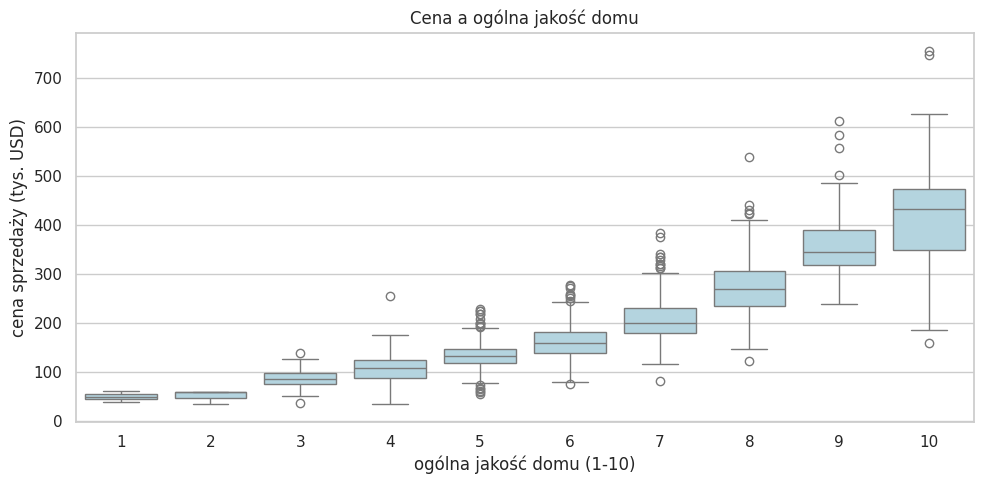

OverallQual,1,2,3,4,5,6,7,8,9,10
count,2.0,3.0,20.0,116.0,397.0,374.0,319.0,168.0,43.0,18.0
median,50150.0,60000.0,86250.0,108000.0,133000.0,160000.0,200141.0,269750.0,345000.0,432390.0


In [25]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data=dane, x="OverallQual", y=dane["SalePrice"] / 1000, color="lightblue", ax=ax)
ax.set_xlabel("ogólna jakość domu (1-10)")
ax.set_ylabel("cena sprzedaży (tys. USD)")
ax.set_title("Cena a ogólna jakość domu")
plt.tight_layout()
plt.show()

dane.groupby("OverallQual")["SalePrice"].agg(["count", "median"]).T

Cena rośnie z oceną jakości prawie jak po schodach: mediana od 50 tys. przy ocenie 1 do 432 tys. przy 10. Przy wyższych ocenach rośnie też rozrzut cen. Ocenę 1 mają tylko 2 domy, a ocenę 2 tylko 3, więc z tych pudełek nie da się wiele wyczytać. Dziwnie wygląda dom z oceną 10 sprzedany poniżej 200 tys.:

In [26]:
dane.loc[(dane["OverallQual"] == 10) & (dane["SalePrice"] < 200_000),
         ["Id", "SalePrice", "GrLivArea", "LotArea", "Neighborhood", "SaleType", "SaleCondition", "YrSold"]]

,Id,SalePrice,GrLivArea,LotArea,Neighborhood,SaleType,SaleCondition,YrSold
523,524,184750,4676,40094,Edwards,New,Partial,2007
1298,1299,160000,5642,63887,Edwards,New,Partial,2008


Takie domy są dwa: jeden to punkt pod pudełkiem, drugi wyznacza koniec dolnego wąsa. Oba to nowe domy (`SaleType = New`) w dzielnicy Edwards, sprzedane jako `Partial`, czyli dom nie był skończony przy ostatniej wycenie. Do tego są ogromne (4676 i 5642 stopy², największe w zbiorze). Cena nie odpowiada więc wartości rynkowej. Wracam do nich w części o powierzchni.

### Wykres słupkowy: instalacja elektryczna

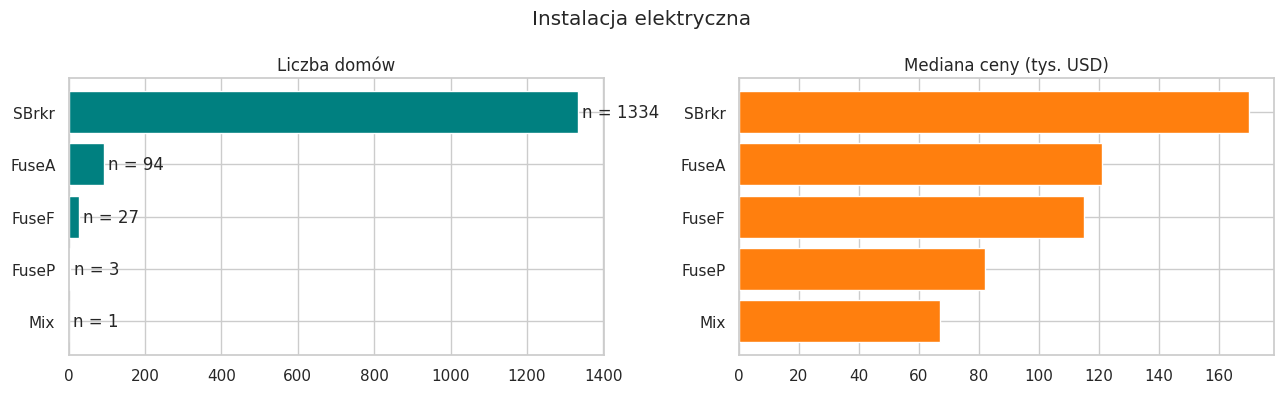

,liczba,mediana
Electrical,,
SBrkr,1334,170000.0
FuseA,94,121250.0
FuseF,27,115000.0
FuseP,3,82000.0
Mix,1,67000.0


In [27]:
elektryka = dane.groupby("Electrical")["SalePrice"].agg(liczba="count", mediana="median").sort_values("liczba", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].barh(elektryka.index, elektryka["liczba"], color="teal")
axes[0].set_title("Liczba domów")
for y, v in enumerate(elektryka["liczba"]):
    axes[0].text(v + 10, y, f"n = {v}", va="center")
axes[1].barh(elektryka.index, elektryka["mediana"] / 1000, color="tab:orange")
axes[1].set_title("Mediana ceny (tys. USD)")
for ax in axes:
    ax.invert_yaxis()
fig.suptitle("Instalacja elektryczna")
plt.tight_layout()
plt.show()
elektryka

1334 domy (91%) mają standardowe bezpieczniki automatyczne (SBrkr), więc ta cecha słabo różnicuje domy. Mediana ceny przy starszych instalacjach jest jednak wyraźnie niższa (121 tys. przy FuseA, 82 tys. przy FuseP). Pewnie nie chodzi o samą instalację, tylko o to, że stare bezpieczniki mają stare, tańsze domy. Mediany z 3 domów (FuseP) i 1 domu (Mix) niewiele znaczą.

### Wykres liniowy: sprzedaż w kolejnych miesiącach

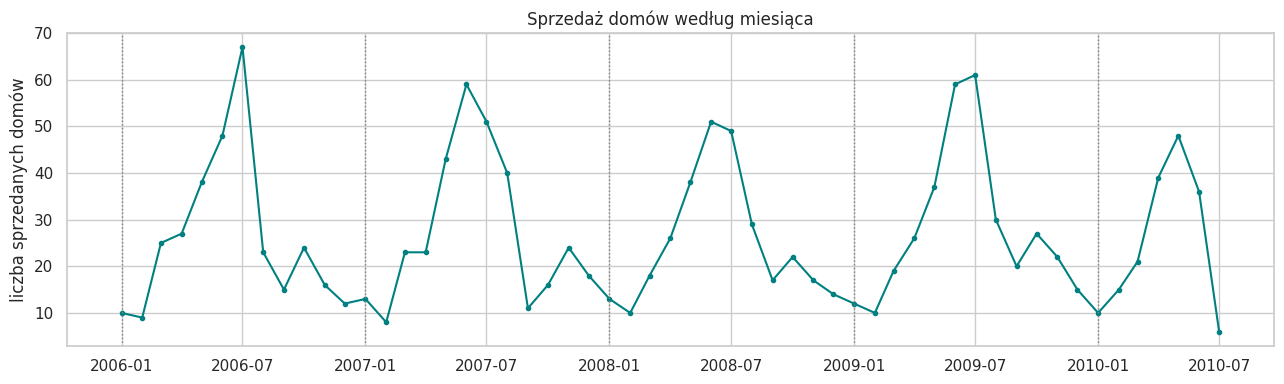

MoSold,1,2,3,4,5,6,7,8,9,10,11,12
sprzedaze,58,52,106,141,204,253,234,122,63,89,79,59


In [28]:
sprzedaz = dane.groupby(["YrSold", "MoSold"]).size()
daty = pd.to_datetime({"year": sprzedaz.index.get_level_values(0), "month": sprzedaz.index.get_level_values(1), "day": 1})

fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(daty, sprzedaz.values, marker="o", ms=3, color="teal")
for rok in range(2006, 2011):
    ax.axvline(pd.Timestamp(f"{rok}-01-01"), color="gray", ls=":", lw=1)
ax.set_ylabel("liczba sprzedanych domów")
ax.set_title("Sprzedaż domów według miesiąca")
plt.tight_layout()
plt.show()

dane.groupby("MoSold").size().to_frame("sprzedaze").T

Sezonowość jest bardzo wyraźna i powtarza się co roku: najwięcej domów sprzedaje się od maja do lipca (najwięcej w czerwcu, łącznie 253), najmniej zimą. Spadek na samym końcu wykresu to nie trend, tylko koniec danych w lipcu 2010. Co ciekawe, mimo kryzysu z 2008 roku liczba sprzedaży w latach 2006-2009 była podobna (304-338 rocznie).

## 7. Hipoteza: większe domy są droższe

Szukam kolumn związanych z powierzchnią ("Area" i "SF" w nazwie).

In [29]:
kolumny_pow = [c for c in dane.columns if "Area" in c or "SF" in c]
kolumny_pow

['LotArea',
 'MasVnrArea',
 'BsmtFinSF1',
 'BsmtFinSF2',
 'BsmtUnfSF',
 'TotalBsmtSF',
 '1stFlrSF',
 '2ndFlrSF',
 'LowQualFinSF',
 'GrLivArea',
 'GarageArea',
 'WoodDeckSF',
 'OpenPorchSF',
 'PoolArea']

Jest ich 14. Najważniejsza to `GrLivArea`, czyli powierzchnia mieszkalna nad ziemią (suma parteru, piętra i powierzchni niskiej jakości, co sprawdziłem w części 3).

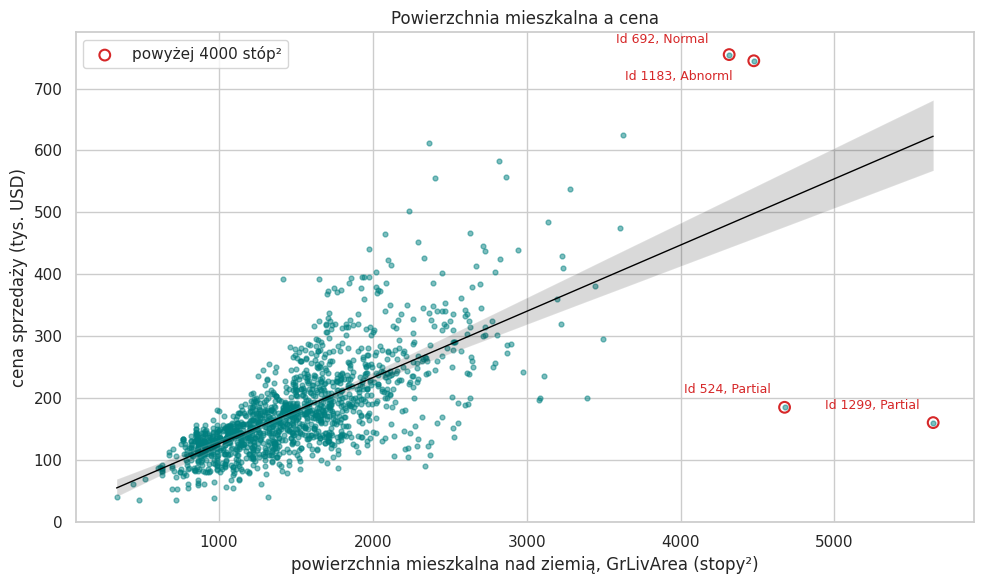

In [30]:
duze = dane["GrLivArea"] > 4000

fig, ax = plt.subplots(figsize=(10, 6))
sns.regplot(data=dane, x="GrLivArea", y=dane["SalePrice"] / 1000, ax=ax,
            scatter_kws={"s": 12, "alpha": 0.5, "color": "teal"}, line_kws={"color": "black", "lw": 1})
ax.scatter(dane.loc[duze, "GrLivArea"], dane.loc[duze, "SalePrice"] / 1000, s=60, facecolors="none",
           edgecolors="tab:red", lw=1.5, label="powyżej 4000 stóp²")
przesuniecia = {524: (-10, 10), 692: (-15, 8), 1183: (-15, -14), 1299: (-10, 10)}
for _, r in dane[duze].iterrows():
    ax.annotate(f"Id {r['Id']}, {r['SaleCondition']}", (r["GrLivArea"], r["SalePrice"] / 1000),
                textcoords="offset points", xytext=przesuniecia[r["Id"]], ha="right", fontsize=9, color="tab:red")
ax.set_xlabel("powierzchnia mieszkalna nad ziemią, GrLivArea (stopy²)")
ax.set_ylabel("cena sprzedaży (tys. USD)")
ax.set_title("Powierzchnia mieszkalna a cena")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

Zależność jest wyraźna i z grubsza liniowa: im większy dom, tym droższy. Widać jednak dwie rzeczy:
- rozrzut cen rośnie z powierzchnią, chmura punktów rozszerza się w prawo jak lejek. Małe domy kosztują podobnie, a duże mogą kosztować bardzo różnie, bo wtedy dużo zależy od jakości i dzielnicy,
- w prawym dolnym rogu są dwa ogromne domy sprzedane za mniej niż 200 tys.

In [31]:
dane.loc[duze, ["Id", "SalePrice", "GrLivArea", "TotalBsmtSF", "LotArea", "OverallQual",
                "Neighborhood", "SaleType", "SaleCondition", "YrSold"]]

,Id,SalePrice,GrLivArea,TotalBsmtSF,LotArea,OverallQual,Neighborhood,SaleType,SaleCondition,YrSold
523,524,184750,4676,3138,40094,10,Edwards,New,Partial,2007
691,692,755000,4316,2444,21535,10,NoRidge,WD,Normal,2007
1182,1183,745000,4476,2396,15623,10,NoRidge,WD,Abnorml,2007
1298,1299,160000,5642,6110,63887,10,Edwards,New,Partial,2008


In [32]:
bez_dwoch = dane[~(duze & (dane["SalePrice"] < 200_000))]
print("korelacja Pearsona GrLivArea i ceny, wszystkie domy:      ", round(dane["GrLivArea"].corr(dane["SalePrice"]), 3))
print("korelacja Pearsona GrLivArea i ceny, bez 2 domów Partial:", round(bez_dwoch["GrLivArea"].corr(bez_dwoch["SalePrice"]), 3))
print()
print("mediana ceny za stopę² (USD):", round((dane["SalePrice"] / dane["GrLivArea"]).median(), 1))
print("cena za stopę² u domów 524 i 1299:",
      (dane.loc[dane["Id"].isin([524, 1299]), "SalePrice"] / dane.loc[dane["Id"].isin([524, 1299]), "GrLivArea"]).round(1).tolist())

korelacja Pearsona GrLivArea i ceny, wszystkie domy:       0.709
korelacja Pearsona GrLivArea i ceny, bez 2 domów Partial: 0.735

mediana ceny za stopę² (USD): 120.1
cena za stopę² u domów 524 i 1299: [39.5, 28.4]


To te same dwa domy, które wyszły przy ocenie jakości (Id 524 i 1299): oba w Edwards, oba to częściowa sprzedaż (`Partial`) nowych domów, a cena za stopę² wynosi 28-40 USD przy medianie 120 USD. Te transakcje nie pokazują rynkowej ceny domu. Same te dwa punkty obniżają korelację z 0,735 do 0,709. Autor zbioru (De Cock) zaleca usunięcie domów powyżej 4000 stóp². Ja przed budową modelu usunąłbym te dwa domy z powodu rodzaju sprzedaży, a nie dlatego, że odstają na wykresie. Pozostałe dwa duże domy (692 i 1183) to najdroższe domy w zbiorze i pasują do trendu, więc ich nie ruszam.

### Która powierzchnia ma najsilniejszy związek z ceną?

Liczę korelację Pearsona (związek liniowy) i Spearmana (związek monotoniczny, mniej wrażliwy na wartości odstające).

In [33]:
korelacje_pow = pd.DataFrame({
    "Pearson": dane[kolumny_pow].corrwith(dane["SalePrice"]),
    "Spearman": dane[kolumny_pow].corrwith(dane["SalePrice"], method="spearman"),
    "udział zer": (dane[kolumny_pow] == 0).mean(),
}).sort_values("Pearson", ascending=False)
korelacje_pow.round(3)

,Pearson,Spearman,udział zer
GrLivArea,0.709,0.731,0.000
GarageArea,0.623,0.649,0.055
TotalBsmtSF,0.614,0.603,0.025
1stFlrSF,0.606,0.575,0.000
MasVnrArea,0.477,0.421,0.590
BsmtFinSF1,0.386,0.302,0.320
WoodDeckSF,0.324,0.354,0.521
2ndFlrSF,0.319,0.294,0.568
OpenPorchSF,0.316,0.478,0.449
LotArea,0.264,0.456,0.000


Najsilniej z ceną wiąże się `GrLivArea` (0,71), potem `GarageArea`, `TotalBsmtSF` i `1stFlrSF` (ok. 0,6). Kolumny, w których prawie wszystkie wartości to zera (`PoolArea`, `BsmtFinSF2`, `LowQualFinSF`), praktycznie nie mają związku z ceną.

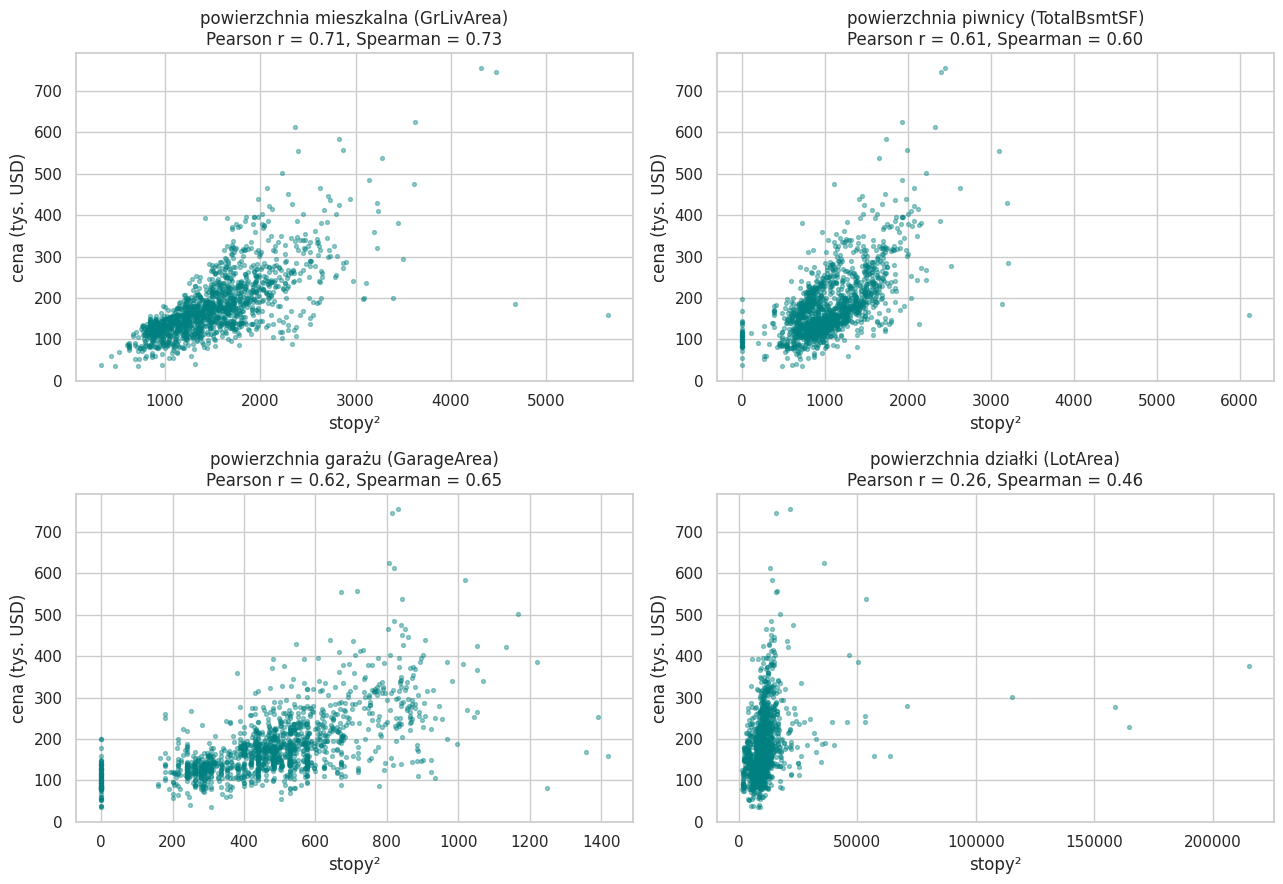

In [34]:
do_wykresu = [("GrLivArea", "powierzchnia mieszkalna"), ("TotalBsmtSF", "powierzchnia piwnicy"),
              ("GarageArea", "powierzchnia garażu"), ("LotArea", "powierzchnia działki")]

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, (kol, opis) in zip(axes.flat, do_wykresu):
    ax.scatter(dane[kol], dane["SalePrice"] / 1000, s=8, alpha=0.4, color="teal")
    r = dane[kol].corr(dane["SalePrice"])
    rs = dane[kol].corr(dane["SalePrice"], method="spearman")
    ax.set_title(f"{opis} ({kol})\nPearson r = {r:.2f}, Spearman = {rs:.2f}")
    ax.set_xlabel("stopy²")
    ax.set_ylabel("cena (tys. USD)")
plt.tight_layout()
plt.show()

Powierzchnia mieszkalna daje najbardziej wydłużoną chmurę punktów, więc ma najsilniejszy związek z ceną. Przy piwnicy i garażu widać pionowy pasek domów z zerem (bez piwnicy albo garażu), który psuje liniowy kształt. Garaż mocno wiąże się z ceną, ale pewnie częściowo dlatego, że nowsze domy mają większe garaże (korelacja `GarageArea` z rokiem budowy to 0,48).

### Czy powierzchnia działki działa tak samo jak powierzchnia domu?

Nie. Pearson r = 0,26 to dużo mniej niż dla domu. Na zwykłym wykresie prawie wszystkie punkty są ściśnięte przy lewej krawędzi, bo kilka działek ma ponad 100 tys. stóp². Dlatego rysuję jeszcze oś logarytmiczną i ceny w grupach wielkości działki.

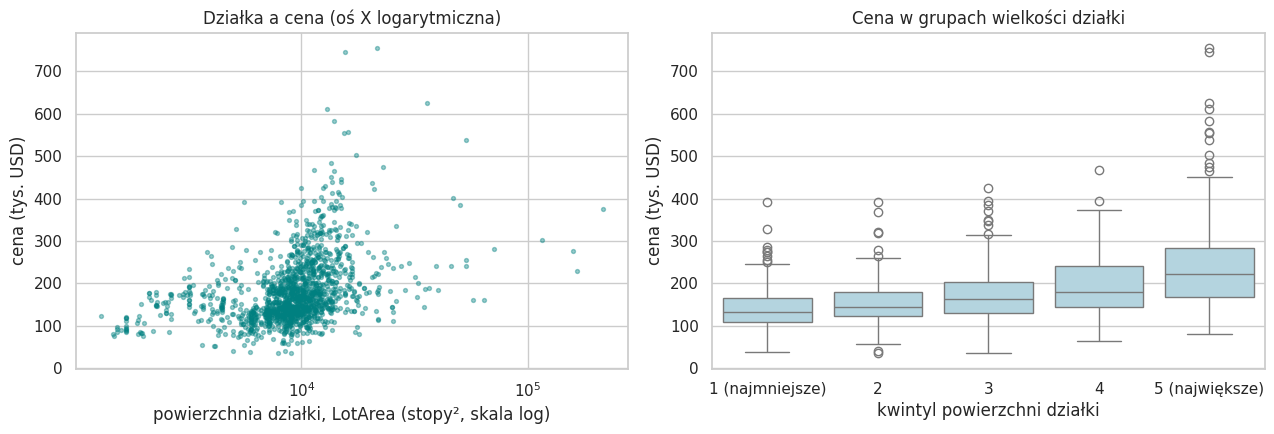

,Id,LotArea,GrLivArea,SalePrice,Neighborhood
313,314,215245,2036,375000,Timber
335,336,164660,1786,228950,Timber
249,250,159000,2144,277000,ClearCr
706,707,115149,1824,302000,ClearCr
451,452,70761,1533,280000,ClearCr


In [35]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].scatter(dane["LotArea"], dane["SalePrice"] / 1000, s=8, alpha=0.4, color="teal")
axes[0].set_xscale("log")
axes[0].set_xlabel("powierzchnia działki, LotArea (stopy², skala log)")
axes[0].set_ylabel("cena (tys. USD)")
axes[0].set_title("Działka a cena (oś X logarytmiczna)")

kat = pd.qcut(dane["LotArea"], 5, labels=["1 (najmniejsze)", "2", "3", "4", "5 (największe)"])
sns.boxplot(x=kat, y=dane["SalePrice"] / 1000, color="lightblue", ax=axes[1])
axes[1].set_xlabel("kwintyl powierzchni działki")
axes[1].set_ylabel("cena (tys. USD)")
axes[1].set_title("Cena w grupach wielkości działki")
plt.tight_layout()
plt.show()

dane.nlargest(5, "LotArea")[["Id", "LotArea", "GrLivArea", "SalePrice", "Neighborhood"]]

W skali logarytmicznej zależność widać lepiej, a Spearman (0,46) jest dużo wyższy niż Pearson (0,26). Związek jest, ale słaby i nieliniowy: większa działka podnosi cenę, ale od pewnego rozmiaru dokładanie ziemi niewiele zmienia. Największa działka w zbiorze (215 tys. stóp², prawie 2 ha) poszła za 375 tys., a dom na niej ma zwykłe 2036 stóp². Największe działki są na obrzeżach (Timber, ClearCr). O cenie decyduje głównie budynek.

**Wniosek:** hipoteza „większe domy są droższe” się potwierdza dla powierzchni domu. Dla powierzchni działki związek jest dużo słabszy.

## 8. Inne zależności

### Mapa korelacji

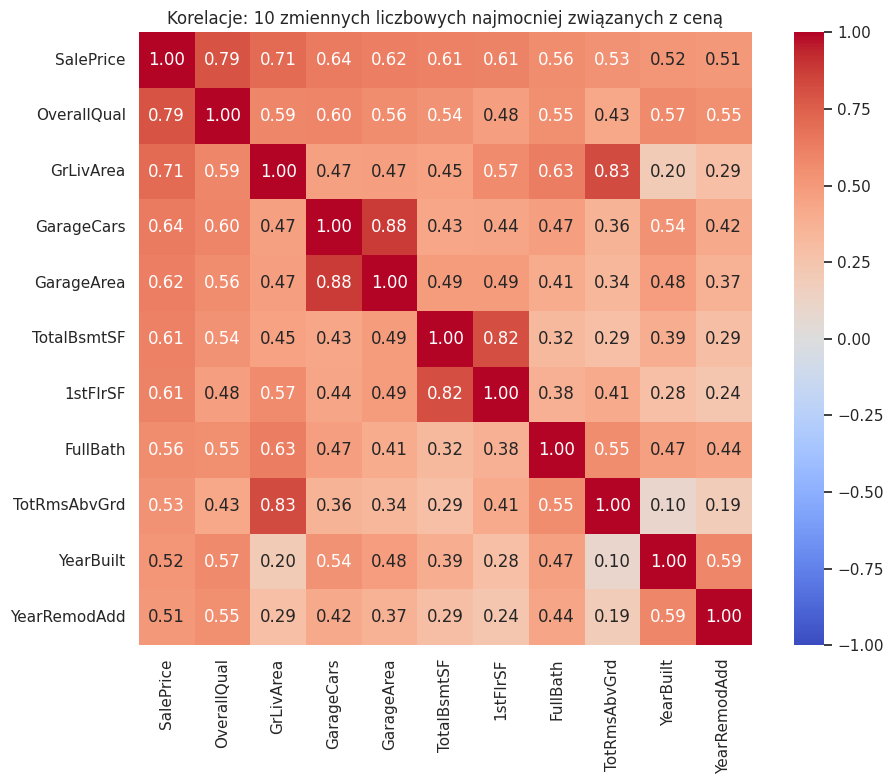

In [36]:
top = dane.select_dtypes("number").drop(columns="Id").corr()["SalePrice"].abs().sort_values(ascending=False).head(11).index

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(dane[top].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True, ax=ax)
ax.set_title("Korelacje: 10 zmiennych liczbowych najmocniej związanych z ceną")
plt.tight_layout()
plt.show()

Z ceną najmocniej wiąże się `OverallQual` (0,79), mocniej niż jakakolwiek powierzchnia. Na mapie widać też pary zmiennych, które mówią prawie to samo: `GarageCars` i `GarageArea` (0,88), `GrLivArea` i `TotRmsAbvGrd` (0,83), `TotalBsmtSF` i `1stFlrSF` (0,82). W modelu liniowym wziąłbym z każdej pary tylko jedną zmienną.

### Dzielnica

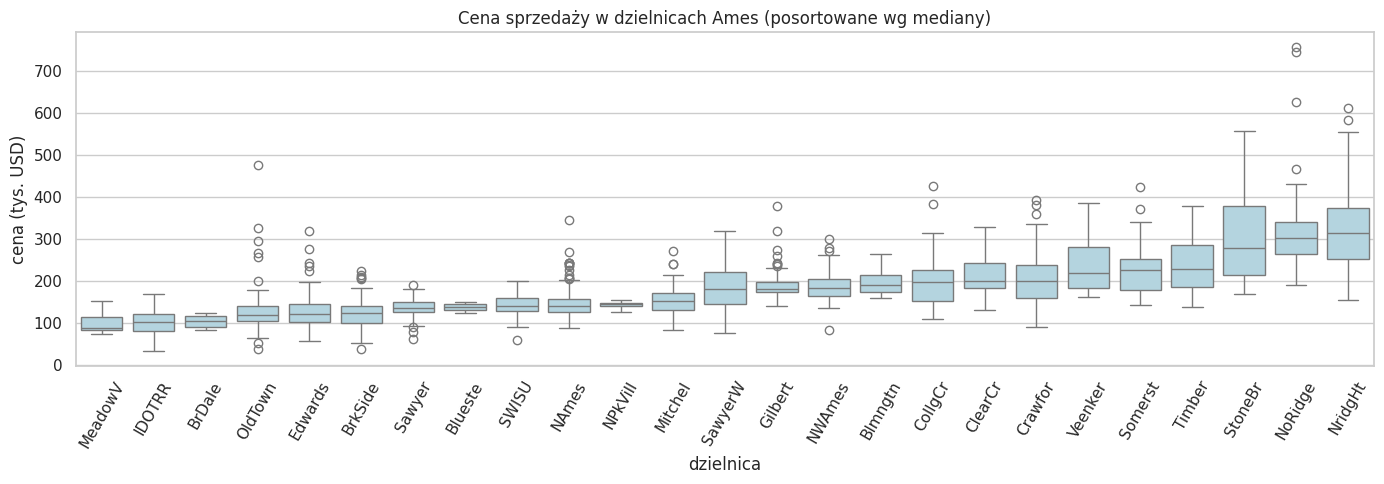

,count,median
Neighborhood,,
MeadowV,17,88000.0
IDOTRR,37,103000.0
BrDale,16,106000.0
NridgHt,77,315000.0
NoRidge,41,301500.0
StoneBr,25,278000.0


In [37]:
kolejnosc = dane.groupby("Neighborhood")["SalePrice"].median().sort_values().index

fig, ax = plt.subplots(figsize=(14, 5))
sns.boxplot(data=dane, x="Neighborhood", y=dane["SalePrice"] / 1000, order=kolejnosc, color="lightblue", ax=ax)
ax.tick_params(axis="x", rotation=60)
ax.set_xlabel("dzielnica")
ax.set_ylabel("cena (tys. USD)")
ax.set_title("Cena sprzedaży w dzielnicach Ames (posortowane wg mediany)")
plt.tight_layout()
plt.show()

dzielnice = dane.groupby("Neighborhood")["SalePrice"].agg(["count", "median"])
pd.concat([dzielnice.nsmallest(3, "median"), dzielnice.nlargest(3, "median")])

Lokalizacja ma ogromne znaczenie. Mediana w najtańszej dzielnicy (MeadowV, 88 tys.) jest ponad 3,5 razy niższa niż w najdroższej (NridgHt, 315 tys.). Trzy najdroższe dzielnice to te same, w których były drogie domy odstające z części 5.

### Rok budowy i rodzaj sprzedaży

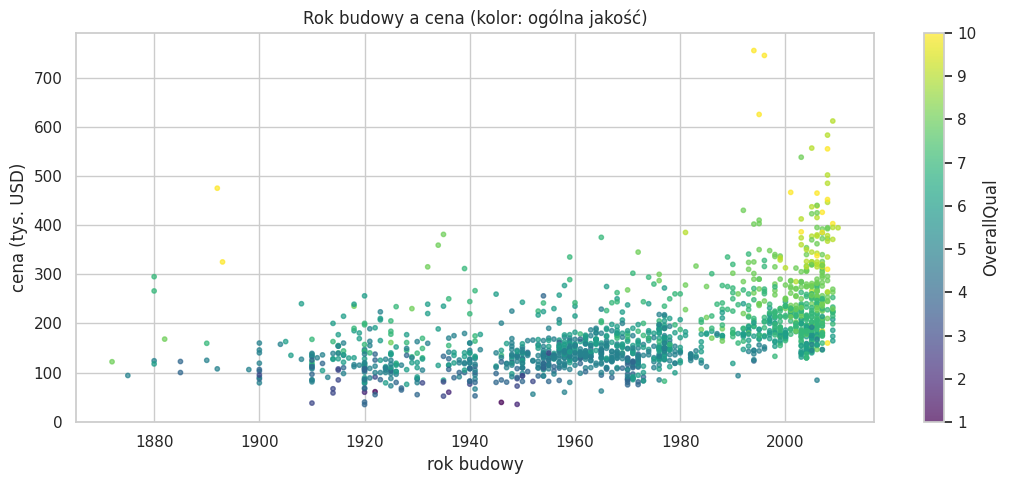

,count,median
SaleCondition,,
Normal,1198,160000.0
Partial,125,244600.0
Abnorml,101,130000.0
Family,20,140500.0
Alloca,12,148145.0
AdjLand,4,104000.0


In [38]:
fig, ax = plt.subplots(figsize=(11, 5))
sc = ax.scatter(dane["YearBuilt"], dane["SalePrice"] / 1000, c=dane["OverallQual"], cmap="viridis", s=10, alpha=0.7)
plt.colorbar(sc, label="OverallQual")
ax.set_xlabel("rok budowy")
ax.set_ylabel("cena (tys. USD)")
ax.set_title("Rok budowy a cena (kolor: ogólna jakość)")
plt.tight_layout()
plt.show()

dane.groupby("SaleCondition")["SalePrice"].agg(["count", "median"]).sort_values("count", ascending=False)

Nowsze domy są średnio droższe i mają lepszą jakość (więcej żółtych punktów po prawej), a od lat 90. ceny bardzo się rozjeżdżają w górę. W tabeli widać, że sprzedaże `Partial` (nowe domy) mają najwyższą medianę, 245 tys., a `Abnorml` (np. przejęcia przez bank) najniższą z dużych grup, 130 tys. Rodzaj sprzedaży wpływa na cenę, więc przy modelu trzeba go uwzględnić albo zostawić tylko sprzedaże `Normal`.

## 9. Podsumowanie

Najważniejsze wnioski:
1. Zmienna docelowa to `SalePrice`. Rozkład jest prawostronnie skośny (średnia 181 tys., mediana 163 tys.), a po zlogarytmowaniu jest prawie normalny.
2. 61 drogich domów powyżej 340 tys. to nie błędy, tylko duże, nowe domy wysokiej jakości w trzech najlepszych dzielnicach. Zostają w danych.
3. Większość braków oznacza brak cechy (basenu, garażu, piwnicy, alejki), co jest opisane w `data_description.txt`. Prawdziwe braki to głównie `LotFrontage` (18%) i kilka pojedynczych wartości. Trzeba też uważać przy wczytywaniu, bo pandas domyślnie zamienia "None" na NaN.
4. Hipoteza „większe domy są droższe” się potwierdza: korelacja `GrLivArea` z ceną to 0,71. Powierzchnia działki ma dużo słabszy i nieliniowy związek z ceną.
5. Z ceną najmocniej wiąże się ogólna jakość domu (`OverallQual`, 0,79). Bardzo ważna jest też dzielnica.
6. Dwa domy (Id 524 i 1299) to częściowa sprzedaż ogromnych domów po zaniżonej cenie. Nie pokazują ceny rynkowej i przed budową modelu bym je usunął.
7. Zakres danych jest wąski: jedno miasto w USA, lata 2006-2010, bez mieszkań w blokach.

Decyzje, które podjąłem:

| Decyzja | Powód |
|---|---|
| Wczytanie z `na_values=["NA"]` | "None" w `MasVnrType` to kategoria, a nie brak danych |
| NA w kolumnach basenu, garażu, piwnicy, kominka, alejki, płotu zamienione na "Brak" | tak mówi opis danych i zgadza się to z zerową powierzchnią |
| `LotFrontage` i pojedyncze braki zostają jako NaN | w EDA nie imputuję; przy modelu mediana w dzielnicy |
| Drogie domy zostają | to prawdziwy segment rynku, a nie błędy |
| Domy 524 i 1299 do usunięcia przed modelem | sprzedaż częściowa, cena nie jest rynkowa |
| Przewidywanie log(ceny) | rozkład ceny jest mocno skośny |